# 03 · El disco más caudal (201) y tres variantes del ángulo de Cobb

## Propósito

En la primera semana, la inspección de la serie 162 mostró que el ángulo calculado por `compute-Cobb-angle.py` podía depender de la inclinación de la cara inferior del disco 201, el más caudal de la máscara. Esto planteó una pregunta: ¿se trata de un caso aislado o sucede también en otras series?

Este cuaderno extiende el análisis a las 447 series de SPIDER v4. Se estudia con qué frecuencia el disco 201 participa en el cálculo, cómo se compara la inclinación sagital de su cara inferior con la de otros discos y cuánto cambia el ángulo al introducir tres variantes del cálculo original.

## Variantes analizadas

- **Original:** el cálculo del script de referencia, ejecutado con la adaptación a NumPy 2 que se describe más abajo.
- **A:** excluye la cara inferior del disco 201.
- **B:** sustituye la fórmula angular original por una formulación alternativa.
- **AB:** combina la exclusión del disco 201 con la fórmula alternativa.

Las variantes A, B y AB son propuestas exploratorias de este proyecto. No forman parte del método publicado por van der Graaf *et al.* ni se consideran correcciones validadas del algoritmo original.

## Alcance

Este es un análisis técnico y descriptivo con máscaras de segmentación de datos públicos. Su objetivo es documentar el comportamiento del algoritmo y explorar su sensibilidad a las modificaciones propuestas. No constituye una validación clínica ni está destinado al diagnóstico de escoliosis.

## Fuentes

- **Algoritmo:** [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`.
- **Dependencia:** [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`.
- **Método publicado:** van der Graaf *et al.*, *European Radiology* (2024), [artículo completo](https://pmc.ncbi.nlm.nih.gov/articles/PMC11364572/).
- **Datos:** [SPIDER v4](https://doi.org/10.5281/zenodo.10159290), licencia CC BY 4.0.

## Antes de ejecutar: datos necesarios

Este cuaderno utiliza las máscaras de SPIDER v4 preparadas en el cuaderno 01. No descarga automáticamente el conjunto de datos.

Los archivos de entrada son:

| Archivo | Ruta en Google Drive | Obligatorio |
|---|---|---|
| `masks.zip` | `MyDrive/PRL/content/datos/spider/masks/masks.zip` | Sí |
| `angulos_cobb.csv` | `MyDrive/PRL/salidas/resultados_semana1/02_compute-Cobb-angle/angulos_cobb.csv` | No, pero permite comparar con la corrida del cuaderno 02 |

El cuaderno comprueba la integridad del archivo comprimido mediante su huella MD5 y verifica las máscaras descomprimidas. Si las máscaras no están disponibles en la carpeta prevista, se extraen desde el archivo comprimido.

Los resultados se guardan en:

`MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/`

El procesamiento se realiza serie por serie. Si Colab se interrumpe, basta con volver a ejecutar la celda de procesamiento: el registro de las series ya procesadas permite continuar con las pendientes.

In [14]:
# 1. Dependencias: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919" openpyxl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [15]:
# 2. Configuración
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_SPIDER = DIR_PRL / "content" / "datos" / "spider"
DIR_SCRIPT = DIR_PRL / "content" / "datos" / "compute-Cobb-angle"
DIR_SEMANA1 = DIR_PRL / "salidas" / "resultados_semana1" / "02_compute-Cobb-angle"     # solo lectura
DIR_SALIDA = DIR_PRL / "salidas" / "resultados_semana2" / "03_disco_caudal_y_variantes"
DIR_FIGURAS = DIR_SALIDA / "figuras_variantes"
DIR_EXTREMOS = DIR_SALIDA / "casos_extremos"
DIR_LOCAL = Path("/content/mascaras_spider")     # copia local temporal: leer de Drive 447 veces es lento

COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"
COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
SHA256_SCRIPT = "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849"   # verificado el 1, el 15 y el 16-oct-2026
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"   # descarga verificada contra Zenodo el 2-oct-2026
N_ESPERADO = 447                                      # series de SPIDER según el cuaderno 01
DISCO_CAUDAL = 201                                    # etiqueta SPIDER del disco más caudal (ver nomenclatura)

assert DIR_SPIDER.exists(), f"No existe {DIR_SPIDER}; revisa con !ls /content/drive/MyDrive/PRL/content/datos"
for d in (DIR_SCRIPT, DIR_FIGURAS, DIR_EXTREMOS):
    d.mkdir(parents=True, exist_ok=True)
print("Entrada:", DIR_SPIDER, "\nScript:", DIR_SCRIPT, "\nSemana 1 (solo lectura):", DIR_SEMANA1, "\nSalida:", DIR_SALIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entrada: /content/drive/MyDrive/PRL/content/datos/spider 
Script: /content/drive/MyDrive/PRL/content/datos/compute-Cobb-angle 
Semana 1 (solo lectura): /content/drive/MyDrive/PRL/salidas/resultados_semana1/02_compute-Cobb-angle 
Salida: /content/drive/MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes


## Script fijado y verificado

Para que el experimento sea reproducible, la celda 3 descarga `compute-Cobb-angle.py` desde un commit concreto y comprueba su huella SHA-256 antes de usarlo. Si la huella no coincide, el cuaderno se detiene.

Al script se le agrega una sola línea en la función `PCA()`, que toma la parte real del resultado de `np.linalg.eig` para que funcione con NumPy 2; las rutas de entrada y salida se ajustan a Colab al ejecutarlo. En el cuaderno 02, esta adaptación se contrastó con la versión original ejecutada con NumPy 1.26 en cinco máscaras, y los ángulos coincidieron hasta la decimotercera cifra decimal.

La copia original, la versión adaptada y sus huellas se guardan en:

`PRL/content/datos/compute-Cobb-angle/`

Así queda documentado qué código se ejecutó, y se reduce el riesgo de atribuir a las variantes diferencias que provengan de cambios accidentales en el entorno o en el algoritmo.

In [16]:
# 3. Descargar el script del commit fijado, verificarlo y preparar la versión ejecutable
import hashlib, requests

def sha256_de(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()

url = f"https://raw.githubusercontent.com/DIAGNijmegen/cobb-angle-algorithm/{COMMIT_SCRIPT}/compute-Cobb-angle.py"
original = requests.get(url, timeout=60).content
sha_obtenido = sha256_de(original)
print("SHA-256 obtenido:", sha_obtenido)
assert sha_obtenido == SHA256_SCRIPT, "El script descargado NO coincide con el verificado; no continuar."

texto = original.decode("utf-8")
LINEA_EIG = "    eigenvalues, eigenvectors = np.linalg.eig(matrix)\n"
PARCHE = "    eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real  # adaptación a NumPy 2 (ver cuaderno 02)\n"
assert texto.count(LINEA_EIG) == 1
ejecutable = texto.replace(LINEA_EIG, LINEA_EIG + PARCHE)

(DIR_SCRIPT / "compute-Cobb-angle.py").write_bytes(original)
(DIR_SCRIPT / "compute-Cobb-angle_numpy2.py").write_text(ejecutable, encoding="utf-8")
(DIR_SCRIPT / "compute-Cobb-angle.py.sha256").write_text(f"{sha_obtenido}  compute-Cobb-angle.py\n")
(DIR_SCRIPT / "compute-Cobb-angle_numpy2.py.sha256").write_text(
    f"{sha256_de(ejecutable.encode('utf-8'))}  compute-Cobb-angle_numpy2.py\n")
(DIR_SCRIPT / "LEEME.txt").write_text(
    "compute-Cobb-angle.py: copia exacta de DIAGNijmegen/cobb-angle-algorithm, commit " + COMMIT_SCRIPT + " (Apache-2.0).\n"
    "compute-Cobb-angle_numpy2.py: la misma copia con una línea agregada en PCA() que toma la parte real de\n"
    "np.linalg.eig para que funcione con NumPy 2. Ver notebooks/02_compute_cobb_angle.ipynb.\n"
    "Los archivos .sha256 se verifican con: sha256sum -c <archivo>.sha256\n", encoding="utf-8")
print("Guardado en", DIR_SCRIPT, "->", sorted(p.name for p in DIR_SCRIPT.iterdir()))

SHA-256 obtenido: 4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849
Guardado en /content/drive/MyDrive/PRL/content/datos/compute-Cobb-angle -> ['LEEME.txt', 'compute-Cobb-angle.py', 'compute-Cobb-angle.py.sha256', 'compute-Cobb-angle_numpy2.py', 'compute-Cobb-angle_numpy2.py.sha256']


## Máscaras: verificación y copia local

Se usan las máscaras que el cuaderno 01 ya descomprimió en Drive. Primero se comprueba que `masks.zip` conserva la huella MD5 verificada contra Zenodo y que cada `.mha` descomprimido es idéntico a su versión dentro del zip; así se asegura que la entrada es la de SPIDER v4 sin alteraciones. Después, las máscaras se copian a una carpeta local de Colab para que la lectura sea rápida.

Estas verificaciones comprueban la integridad de los archivos de entrada, pero no evalúan la exactitud anatómica de las segmentaciones.

In [17]:
# 4. Verificar las máscaras contra masks.zip y copiarlas a disco local
import zipfile, shutil

def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

zip_masks = next((p for p in (DIR_SPIDER / "masks.zip", DIR_SPIDER / "masks" / "masks.zip") if p.exists()), None)
assert zip_masks is not None, "No encontré masks.zip en datos/spider ni en datos/spider/masks"
md5_zip = md5_archivo(zip_masks)
print("MD5 de masks.zip:", md5_zip, "| coincide con la verificada:", md5_zip == MD5_MASKS_ZIP)
assert md5_zip == MD5_MASKS_ZIP

en_drive = {p.name: p for p in (DIR_SPIDER / "masks").rglob("*.mha")}
if not en_drive:   # el cuaderno 01 no se ha corrido: descomprimir aquí
    with zipfile.ZipFile(zip_masks) as z:
        z.extractall(DIR_SPIDER / "masks")
    en_drive = {p.name: p for p in (DIR_SPIDER / "masks").rglob("*.mha")}

DIR_LOCAL.mkdir(parents=True, exist_ok=True)
distintos = []
with zipfile.ZipFile(zip_masks) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    for nombre, miembro in miembros.items():
        datos_zip = z.read(miembro)
        ruta = en_drive.get(nombre)
        if ruta is None or hashlib.md5(ruta.read_bytes()).hexdigest() != hashlib.md5(datos_zip).hexdigest():
            distintos.append(nombre)
        (DIR_LOCAL / nombre).write_bytes(datos_zip)   # la copia local sale del zip verificado

mascaras = sorted(DIR_LOCAL.glob("*.mha"))
print(f"{len(miembros)} máscaras en el zip | {len(en_drive)} en Drive | {len(distintos)} distintas o faltantes en Drive")
if distintos:
    print("Revisar en Drive (se usa la copia del zip):", distintos[:10])
assert len(mascaras) == N_ESPERADO, f"Se esperaban {N_ESPERADO} máscaras y hay {len(mascaras)}"

MD5 de masks.zip: 49861ff25a0108b3b69d0ce808ae51dc | coincide con la verificada: True
447 máscaras en el zip | 447 en Drive | 0 distintas o faltantes en Drive


## Nomenclatura de las etiquetas en las máscaras de SPIDER

Cada estructura de una máscara de SPIDER tiene un número entero: las vértebras van de 1 en adelante, el canal medular es 100 y los discos van de 201 en adelante. El script usa esta convención para separarlas (vértebras < 100, canal = 100, discos > 200). El sacro no está segmentado.

La numeración va **de abajo hacia arriba**: la vértebra lumbar más caudal es la 1. Según el artículo del dataset, este número **no es una etiqueta anatómica**: la vértebra 1 no es necesariamente L5, porque una vértebra de transición lumbosacra ocurre en el 35,5 % de la población y una sexta lumbar en el 6,6 %, y el campo de visión de estas RM no permite contar los niveles desde arriba (van der Graaf *et al.*, *Sci Data* 2024;11:264, doi:[10.1038/s41597-024-03090-w](https://doi.org/10.1038/s41597-024-03090-w)).

Al ordenar por altura las estructuras de varias máscaras (185_t1, 1_t1 y 162_t2_SPACE), el disco 20k aparece siempre justo debajo de la vértebra k. Así, el disco 201 es el que queda entre la vértebra lumbar más caudal y el sacro. Esta relación se comprobó en esas máscaras; el artículo no la enuncia de forma explícita.

Equivalencia **solo si la anatomía es típica** (cinco lumbares, sin vértebra de transición). Es una inferencia, no un dato del dataset:

| Etiqueta SPIDER | Nivel con anatomía típica |
|-|-|
| vértebra 1 / disco 201 | L5 / L5–S1 |
| vértebra 2 / disco 202 | L4 / L4–L5 |
| vértebra 3 / disco 203 | L3 / L3–L4 |
| vértebra 4 / disco 204 | L2 / L2–L3 |
| vértebra 5 / disco 205 | L1 / L1–L2 |
| vértebra 6 / disco 206 | T12 / T12–L1 |
| vértebra 7 en adelante | torácicas que alcanzan a entrar en el campo de visión |

En este cuaderno los niveles se nombran siempre con la etiqueta de SPIDER (por ejemplo, "disco 201, el más caudal; probablemente L5–S1"), nunca solo con el nombre anatómico.

## Definición matemática de las variantes

### Representación de las caras discales

El algoritmo ajusta un plano a la cara superior y otro a la cara inferior de cada disco intervertebral. Cada plano se representa mediante una normal unitaria:

$$
\mathbf{n}=(n_x,n_y,n_z)
$$

Las componentes corresponden a los ejes de la máscara reorientada y remuestreada a 0,5 mm: $x$ representa el eje lateral, $y$ el anteroposterior y $z$ el craneocaudal. Esta convención es coherente con la proyección utilizada por el script mediante `mask.sum(1)`.

Dentro de `vertices_to_plane_surface`, el algoritmo orienta las normales para que cumplan $n_z\geq 0$. Esto permite comparar las orientaciones de las caras con una convención de signos común.

### Ángulo original

El script describe la inclinación de cada cara mediante:

$$
\theta_{\mathrm{orig}}=
\arctan\left(\frac{n_x}{n_z}\right)
$$

Esta expresión es la pendiente lateral de la traza del plano en una proyección coronal. El ángulo final se obtiene buscando la mayor diferencia absoluta entre la cara inferior de un disco y la cara superior de otro disco situado más cranealmente:

$$
C_{\mathrm{orig}}=
\max_{i,j}
\left|\theta_{\mathrm{sup},j}
-\theta_{\mathrm{inf},i}\right|
$$

donde los pares $(i,j)$ son los candidatos admitidos por el algoritmo original. Esta notación resume el criterio geométrico; la implementación y sus restricciones de selección siguen siendo las del script de referencia.

### Variante A: exclusión del disco 201

La variante A repite el cálculo original, pero excluye la cara inferior del disco 201, la etiqueta más caudal de las máscaras analizadas.

Como esta es la única cara del disco 201 que puede participar en los pares considerados por el algoritmo, la variante equivale a retirar esa cara de los candidatos y volver a calcular el máximo:

$$
C_A=
\max_{(i,j)\in\mathcal{P}_A}
\left|\theta_{\mathrm{sup},j}
-\theta_{\mathrm{inf},i}\right|
$$

Aquí, $\mathcal{P}_A$ representa el conjunto de pares candidatos después de excluir esa cara.

Al tratarse de una exclusión de candidatos, el resultado de A no puede superar al original, siempre que ambas variantes utilicen el mismo conjunto inicial de candidatos y las mismas reglas de selección:

$$
C_A\leq C_{\mathrm{orig}}
$$

Esta comparación permite estudiar cuánto influye el disco 201 en el ángulo final, sin modificar la fórmula angular.

### Variante B: formulación alternativa

La variante B sustituye la expresión original por:

$$
\theta_B=\arcsin(n_x)
$$

Esta expresión cuantifica una componente distinta de la orientación de la cara. Cuando $n_y=0$, las dos formulaciones coinciden bajo la convención de normales utilizada; cuando existe una componente anteroposterior, sus resultados pueden diferir.

Para cada cara, se cumple:

$$
\left|\arcsin(n_x)\right|
\leq
\left|\arctan\left(\frac{n_x}{n_z}\right)\right|
$$

bajo las condiciones de normalización y orientación indicadas. Esta desigualdad se refiere a la inclinación de una cara individual; no garantiza por sí sola que el ángulo final de B sea menor que el original, porque el resultado se obtiene mediante la diferencia entre dos caras y la selección del máximo.

Además, las dos fórmulas están relacionadas de forma exacta. Si $\varphi=\arctan(n_y/n_z)$ es la inclinación sagital de la cara, la normalización $n_x^2+n_y^2+n_z^2=1$ implica que $n_z=\cos\varphi\,\cos\theta_B$, y por lo tanto:

$$
\tan\theta_{\mathrm{orig}}=\frac{\tan\theta_B}{\cos\varphi}
$$

Es decir, la fórmula original amplifica la tangente de la inclinación lateral por un factor $1/\cos\varphi$, que vale 1,01 para una inclinación sagital de 8° y 1,19 para una de 33°. Esto explica la desigualdad anterior y por qué las dos fórmulas se separan más en las caras con mucha inclinación sagital. La celda 7f comprueba esta relación con los datos.

Ninguna de las dos expresiones es, por sí misma, la única medida correcta de la inclinación lateral, y dos construcciones sintéticas, calculadas de forma analítica, lo muestran. Si la cara se construye con una pendiente lateral de 8° y una pendiente sagital de 35° (el plano $z = x\tan 8° + y\tan 35°$), la fórmula original recupera exactamente los 8,0°, mientras que $\arcsin(n_x)$ da 6,6°. Si, en cambio, se aplica una rotación lateral de 8° seguida de una rotación sagital de 35°, ocurre lo contrario: $\arcsin(n_x)$ recupera exactamente los 8,0° y la fórmula original da 9,7°. Cada fórmula es exacta para una forma distinta de describir la orientación del plano, y ambas se separan más entre sí cuanto mayor es la inclinación sagital de la cara.

### Variante AB: combinación de cambios

La variante AB combina las modificaciones anteriores: excluye la cara inferior del disco 201 y utiliza $\arcsin(n_x)$ para describir la inclinación de las caras restantes.

Su objetivo es explorar si la exclusión del disco 201 y el cambio de formulación tienen efectos independientes, acumulativos o dependientes entre sí.

### Interpretación

Las variantes A, B y AB son propuestas exploratorias de este proyecto. No forman parte del método publicado por van der Graaf *et al.* y no se presentan como correcciones validadas del algoritmo original.

## Qué se guarda de cada cara y cómo se calculan las variantes

La celda 5 corre el script sobre una máscara a la vez, igual que el cuaderno 02, y en lugar de quedarse solo con el ángulo final guarda una fila por cara de disco en `planos_por_disco.csv`. Cada fila tiene la normal y el punto del plano tal como los dejó el script, con todos sus decimales, el número de vértices que usó el ajuste, el ángulo coronal que calculó el script, $\arcsin(n_x)$, la inclinación sagital $\arctan(n_y/n_z)$ y una marca de si esa cara forma parte del par elegido. Con ese archivo, cualquier variante futura se calcula en segundos sin volver a correr el script.

El signo de la inclinación sagital depende de la dirección del eje $y$ después de `reorient_image`, que este cuaderno no verifica contra la anatomía; por eso se reporta también su valor absoluto y no se interpreta el signo como anterior o posterior.

La función `maximo_como_el_script` de la celda 5a construye la misma matriz de pares que el script (filas: cara inferior del disco caudal; columnas: cara superior del disco craneal; solo pares con etiqueta inferior menor que la superior), toma el valor absoluto y el máximo con `argmax`, de modo que los empates se resuelven igual. Las variantes solo cambian qué columna se usa como ángulo de cada cara y qué discos se excluyen.

In [18]:
# 5a. Definición de las variantes (no corre nada todavía)
import numpy as np, pandas as pd

VARIANTES = {   # nombre: (ángulo por cara que se usa, discos excluidos)
    "original":  ("angulo_coronal_script", ()),
    "A_sin_201": ("angulo_coronal_script", (DISCO_CAUDAL,)),
    "B_arcsen":  ("arcsen_nx", ()),
    "AB":        ("arcsen_nx", (DISCO_CAUDAL,)),
}

def maximo_como_el_script(caras, columna, excluir=()):
    """Misma matriz y mismo argmax que compute-Cobb-angle.py, con la columna y las exclusiones indicadas."""
    inf = caras[caras["cara"] == "inferior"].set_index("disco")[columna]
    sup = caras[caras["cara"] == "superior"].set_index("disco")[columna]
    labels = sorted(int(l) for l in inf.index if int(l) not in excluir)
    if len(labels) < 2:
        return np.nan, np.nan, np.nan
    overview = np.zeros([len(labels), len(labels)])
    for i, l_inf in enumerate(labels):
        for j, l_sup in enumerate(labels):
            if l_inf < l_sup:
                overview[i, j] = sup[l_sup] - inf[l_inf]
    overview = np.absolute(overview)
    i, j = np.unravel_index(overview.argmax(), overview.shape)
    return float(overview.max()), labels[i], labels[j]

def variantes_de(caras):
    fila = {}
    for nombre, (columna, excluir) in VARIANTES.items():
        angulo, d_inf, d_sup = maximo_como_el_script(caras, columna, excluir)
        fila[f"angulo_{nombre}"], fila[f"disco_inf_{nombre}"], fila[f"disco_sup_{nombre}"] = angulo, d_inf, d_sup
    return fila

def filas_de_planos(serie, ns):
    """Una fila por cara de disco con los planos que ajustó el script (objetos Disc en ns['all_discs'])."""
    labels, discos = [int(l) for l in ns["labels"]], ns["all_discs"]
    d_inf, d_sup = labels[ns["index_highest_vertebra"]], labels[ns["index_lowest_vertebra"]]   # nombres del script
    filas = []
    for lab in labels:
        d = discos[lab]
        for cara, normal, punto, angulo, seleccion, elegida in (
                ("inferior", d.normal_L, d.point_L, d.angle_L, d.lower, lab == d_inf),
                ("superior", d.normal_U, d.point_U, d.angle_U, d.upper, lab == d_sup)):
            n = np.asarray(normal, dtype=float)
            u = n / np.linalg.norm(n)
            filas.append({
                "serie": serie, "disco": lab, "cara": cara,
                "nx": n[0], "ny": n[1], "nz": n[2],
                "px": punto[0], "py": punto[1], "pz": punto[2],
                "n_vertices": int(np.sum(seleccion)),
                "angulo_coronal_script": float(angulo),                       # atan(nx/nz), calculado por el script
                "arcsen_nx": float(np.degrees(np.arcsin(np.clip(u[0], -1, 1)))),
                "inclinacion_sagital": float(np.degrees(np.arctan(u[1] / u[2]))),
                "elegida_script": bool(elegida),
                "angulo_script_serie": float(ns["angle"]),
            })
    return filas

ESTILOS = [   # variante, color, trazo, grosor; se dibujan en este orden, así B queda encima del original
    ("original",  "#e8384f", "-",  2.4),
    ("A_sin_201", "#ffa630", "--", 1.8),
    ("B_arcsen",  "#4cc9f0", ":",  2.0),
]

def dibujar_variantes(ax, serie, ns, v):
    """Proyección coronal del script con todas las caras (blanco) y el par de cada variante encima."""
    discos, a_tangente = ns["all_discs"], ns["plane_to_tangent"]
    ax.imshow(ns["image2D"].T)
    for lab, d in discos.items():
        for punto, normal in ((d.point_L, d.normal_L), (d.point_U, d.normal_U)):
            x, z = a_tangente(d.verts, punto, normal)
            ax.plot(x, z, color="white", lw=0.6)
        ax.text(d.verts[:, 0].max() + 6, d.verts[:, 2].mean(), str(lab), fontsize=7, va="center", color="#dddddd")
    for nombre, color, trazo, grosor in ESTILOS:
        d_inf, d_sup = v[f"disco_inf_{nombre}"], v[f"disco_sup_{nombre}"]
        if pd.isna(d_inf):
            continue
        for k, (lab, cara) in enumerate(((int(d_inf), "inferior"), (int(d_sup), "superior"))):
            d = discos[lab]
            punto, normal = (d.point_L, d.normal_L) if cara == "inferior" else (d.point_U, d.normal_U)
            x, z = a_tangente(d.verts, punto, normal)
            ax.plot(x, z, color=color, ls=trazo, lw=grosor,
                    label=(f"{nombre}: {v[f'angulo_{nombre}']:.2f}° ({int(d_inf)}–{int(d_sup)})" if k == 0 else None))
    ax.invert_yaxis(); ax.invert_xaxis(); ax.axis("off")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.16), fontsize=7, frameon=False, ncol=1)
    ab = f"{v['angulo_AB']:.2f}° ({int(v['disco_inf_AB'])}–{int(v['disco_sup_AB'])})" if not pd.isna(v["angulo_AB"]) else "no calculable"
    ax.set_title(f"{serie}\nAB (sin 201 y arcsen): {ab}", fontsize=9)
print("Variantes definidas:", ", ".join(VARIANTES))

Variantes definidas: original, A_sin_201, B_arcsen, AB


## Ejecución

Se corre el script tal cual sobre **una máscara a la vez**, igual que en el cuaderno 02, y se leen del espacio de nombres del script los objetos `Disc` con sus planos. Primero se agregan las caras de la serie a `planos_por_disco.csv` y después la serie a `registro_corrida.csv`; si Colab se corta entre las dos escrituras, la serie se vuelve a procesar y la celda 6 descarta las filas repetidas.

No se vuelven a guardar las figuras originales del script, que son idénticas a las de `resultados_semana1/02_compute-Cobb-angle/figuras/`. En su lugar, si `GUARDAR_FIGURAS_VARIANTES` está activo, cada serie deja en `figuras_variantes/` una figura con el par que elige cada variante: rojo continuo para el original, naranja discontinuo para A y azul punteado para B; el par de AB va en el título. Cuando dos variantes eligen el mismo par, las líneas se superponen.

In [19]:
# 5. Correr el script en cada máscara y guardar los planos de cada cara (retoma donde iba si se interrumpe)
GUARDAR_FIGURAS_VARIANTES = True   # @param {type:"boolean"}
import csv, time, tempfile, traceback, io, contextlib, shutil
import matplotlib
matplotlib.use("Agg")                   # el script llama plt.show(); así no se intenta abrir 447 ventanas
import matplotlib.pyplot as plt

CSV_PLANOS = DIR_SALIDA / "planos_por_disco.csv"
CSV_REGISTRO = DIR_SALIDA / "registro_corrida.csv"
COLUMNAS_REGISTRO = ["serie", "angulo_script", "n_discos", "estado", "segundos", "detalle"]
codigo = (DIR_SCRIPT / "compute-Cobb-angle_numpy2.py").read_text(encoding="utf-8")

def ejecutar_script(ruta):
    """Corre compute-Cobb-angle_numpy2.py sobre una máscara y devuelve su espacio de nombres."""
    with tempfile.TemporaryDirectory() as ti, tempfile.TemporaryDirectory() as to:
        shutil.copy(ruta, Path(ti) / ruta.name)
        fuente = (codigo.replace("mask_path = Path('path/to/spine/segmentations')", f"mask_path = Path({ti!r})")
                        .replace("image_path = Path('path/to/output/images')", f"image_path = Path({to!r})"))
        ns = {"__name__": "compute_cobb_angle"}
        mostrar_original, figuras_previas = plt.show, set(plt.get_fignums())
        plt.show = lambda *a, **k: None          # que no aparezca la figura propia del script
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(fuente, "compute-Cobb-angle_numpy2.py", "exec"), ns)
        finally:
            plt.show = mostrar_original
            for num in set(plt.get_fignums()) - figuras_previas:   # cierra solo la figura que abrió el script
                plt.close(num)
    return ns

hechas = set(pd.read_csv(CSV_REGISTRO, dtype={"serie": str})["serie"]) if CSV_REGISTRO.exists() else set()
if not CSV_REGISTRO.exists():
    with open(CSV_REGISTRO, "w", newline="") as f:
        csv.writer(f).writerow(COLUMNAS_REGISTRO)
pendientes = [m for m in mascaras if m.stem not in hechas]
print(f"Ya procesadas: {len(hechas)} | pendientes: {len(pendientes)}")

for i, ruta in enumerate(pendientes, 1):
    t0 = time.time()
    angulo, n_discos, estado, detalle = np.nan, 0, "error", ""
    try:
        ns = ejecutar_script(ruta)
        angulo = float(ns["all_scans"][ruta.stem])
        if angulo == 9999:
            estado = "sin_discos (el script asigna 9999)"
        else:
            caras = pd.DataFrame(filas_de_planos(ruta.stem, ns))
            caras.to_csv(CSV_PLANOS, mode="a", header=not CSV_PLANOS.exists(), index=False)
            n_discos, estado = int(caras["disco"].nunique()), "ok"
            if GUARDAR_FIGURAS_VARIANTES:
                fig, ax = plt.subplots(figsize=(4.8, 6.6))
                dibujar_variantes(ax, ruta.stem, ns, variantes_de(caras))
                fig.savefig(DIR_FIGURAS / f"{ruta.stem}.png", dpi=110, facecolor="white", bbox_inches="tight")
    except Exception as e:
        detalle = f"{type(e).__name__}: {e}"
        traceback.print_exc()
    finally:
        plt.close("all")
    with open(CSV_REGISTRO, "a", newline="") as f:
        csv.writer(f).writerow([ruta.stem, angulo, n_discos, estado, round(time.time() - t0, 1), detalle])
    if i % 25 == 0 or i == len(pendientes):
        print(f"{i}/{len(pendientes)} · última: {ruta.stem} = {angulo:.2f}° ({estado})")

Ya procesadas: 447 | pendientes: 0


## Tabla de variantes y controles

Antes de describir los resultados, la celda 6 hace cuatro comprobaciones:

1. Todas las normales guardadas tienen $n_z > 0$, y $\arctan(n_x/n_z)$ calculado desde ellas coincide con el ángulo que guardó el script. Si no fuera así, las variantes B y AB no serían comparables con el original.
2. La columna original, recalculada desde los planos guardados, reproduce exactamente el ángulo y el par de discos que devolvió el script en esta misma corrida. Esta es la comprobación que garantiza que las cuatro columnas se calculan sobre la misma base.
3. Si está disponible `angulos_cobb.csv` del cuaderno 02, esta corrida se compara con la de ese cuaderno. Una diferencia no detiene la ejecución, pero debe revisarse antes de usar los resultados, porque indicaría que algo del entorno cambió entre corridas.
4. La variante A nunca da un ángulo mayor que el original. Como A solo retira candidatos y conserva las reglas de selección, una violación indicaría que cambió algo más que la exclusión del disco 201.

`angulos_variantes.csv` tiene una fila por serie con el ángulo y el par de cada variante, las diferencias respecto al original y la huella MD5 de la máscara. Esa huella importa porque 107 parejas T1/T2 del mismo estudio comparten exactamente la misma máscara, como se encontró en el cuaderno 02: contarlas dos veces infla los conteos. Por eso, la columna `mascara_unica` marca la primera aparición de cada máscara, y las descripciones de la celda 7 se reportan con y sin duplicados.

In [20]:
# 6. Variantes por serie, con los controles de consistencia
import hashlib
planos = (pd.read_csv(CSV_PLANOS, dtype={"serie": str})
            .drop_duplicates(["serie", "disco", "cara"], keep="last"))
registro = pd.read_csv(CSV_REGISTRO, dtype={"serie": str}).drop_duplicates("serie", keep="last")
print("Series por estado:\n" + registro["estado"].value_counts().to_string())

# Control 1: normales hacia arriba y ángulo del script reproducible desde ellas
assert (planos["nz"] > 0).all(), "Hay normales con nz <= 0: revisar antes de comparar variantes"
dif_formula = (np.degrees(np.arctan(planos["nx"] / planos["nz"])) - planos["angulo_coronal_script"]).abs().max()
print(f"\nControl 1 · |atan(nx/nz) − ángulo del script|, máximo en {len(planos)} caras: {dif_formula:.2e}°")
assert dif_formula < 1e-9

filas = []
for serie, caras in planos.groupby("serie", sort=False):
    elegidas = caras[caras["elegida_script"]]
    filas.append({"serie": serie, "n_discos": caras["disco"].nunique(),
                  "angulo_script": caras["angulo_script_serie"].iloc[0],
                  "disco_inf_script": int(elegidas.loc[elegidas["cara"] == "inferior", "disco"].iloc[0]),
                  "disco_sup_script": int(elegidas.loc[elegidas["cara"] == "superior", "disco"].iloc[0]),
                  **variantes_de(caras)})
var = pd.DataFrame(filas)

# Control 2: la columna original es exactamente lo que devolvió el script
dif_original = (var["angulo_original"] - var["angulo_script"]).abs().max()
mismo_par = ((var["disco_inf_original"] == var["disco_inf_script"]) & (var["disco_sup_original"] == var["disco_sup_script"])).all()
print(f"Control 2 · |original − script|, máximo en {len(var)} series: {dif_original:.2e}° · mismo par en todas: {mismo_par}")
assert dif_original < 1e-9 and mismo_par

# Control 3: esta corrida frente a la de la semana 1 (no detiene el cuaderno, pero hay que revisarlo)
CSV_SEMANA1 = DIR_SEMANA1 / "angulos_cobb.csv"
if CSV_SEMANA1.exists():
    s1 = pd.read_csv(CSV_SEMANA1, dtype={"serie": str}).drop_duplicates("serie", keep="last")
    comp = var.merge(s1[["serie", "angulo_cobb_grados"]], on="serie", how="outer", indicator=True)
    dif_s1 = (comp["angulo_script"] - comp["angulo_cobb_grados"]).abs()
    print(f"Control 3 · series en ambas corridas: {(comp['_merge'] == 'both').sum()} · "
          f"solo en una: {(comp['_merge'] != 'both').sum()} · |esta − semana 1| máximo: {dif_s1.max():.2e}°")
    if dif_s1.max() > 1e-6 or (comp["_merge"] != "both").any():
        print("ATENCIÓN: esta corrida no reproduce la de la semana 1. Revisar antes de usar los resultados:")
        print(comp.loc[(dif_s1 > 1e-6) | (comp["_merge"] != "both"), ["serie", "angulo_script", "angulo_cobb_grados", "_merge"]].to_string(index=False))
else:
    print("Control 3 · no está angulos_cobb.csv de la semana 1; no se comparó con esa corrida.")

# Metadatos mínimos y huella de la máscara (para no contar dos veces las máscaras compartidas)
var["estudio"] = var["serie"].str.split("_", n=1).str[0]
sufijo = var["serie"].str.split("_", n=1).str[1].str.lower()
var["secuencia"] = np.where(sufijo.str.contains("space", na=False), "t2_SPACE", sufijo)
md5 = {p.stem: hashlib.md5(p.read_bytes()).hexdigest() for p in mascaras}
var["mascara_md5"] = var["serie"].map(md5)
var = var.sort_values("serie", key=lambda s: s.str.split("_").str[0].astype(int) * 10
                      + s.str.split("_", n=1).str[1].map({"t1": 0, "t2": 1}).fillna(2)).reset_index(drop=True)
var["mascara_unica"] = ~var["mascara_md5"].duplicated(keep="first")

var["par_original_incluye_201"] = var["disco_inf_original"] == DISCO_CAUDAL
for nombre in ("A_sin_201", "B_arcsen", "AB"):
    var[f"dif_original_menos_{nombre}"] = var["angulo_original"] - var[f"angulo_{nombre}"]
    var[f"cambia_par_{nombre}"] = ((var[f"disco_inf_{nombre}"] != var["disco_inf_original"])
                                   | (var[f"disco_sup_{nombre}"] != var["disco_sup_original"]))
assert (var["dif_original_menos_A_sin_201"] >= -1e-12).all(), "La variante A no puede superar al original"

orden = (["serie", "estudio", "secuencia", "n_discos", "mascara_md5", "mascara_unica", "par_original_incluye_201"]
         + [f"{p}_{n}" for n in VARIANTES for p in ("angulo", "disco_inf", "disco_sup")]
         + [c for c in var.columns if c.startswith(("dif_", "cambia_par_"))])
var = var[orden]
var.to_csv(DIR_SALIDA / "angulos_variantes.csv", index=False)
print(f"\nGuardado angulos_variantes.csv: {len(var)} series · {var['mascara_unica'].sum()} máscaras únicas")
print(var[["serie", "angulo_original", "angulo_A_sin_201", "angulo_B_arcsen", "angulo_AB"]].head().round(2).to_string(index=False))

Series por estado:
estado
ok    447

Control 1 · |atan(nx/nz) − ángulo del script|, máximo en 6294 caras: 9.77e-15°
Control 2 · |original − script|, máximo en 447 series: 5.33e-15° · mismo par en todas: True
Control 3 · series en ambas corridas: 447 · solo en una: 0 · |esta − semana 1| máximo: 0.00e+00°

Guardado angulos_variantes.csv: 447 series · 340 máscaras únicas
serie  angulo_original  angulo_A_sin_201  angulo_B_arcsen  angulo_AB
 1_t1            47.29             47.29            47.11      47.11
 1_t2            47.29             47.29            47.11      47.11
 2_t1             3.19              3.19             3.18       3.18
 2_t2             3.30              3.30             3.29       3.29
 3_t1            12.10             12.10            11.68      11.68


## Descripción del resultado

Todo lo que sigue es descriptivo. No hay prueba de hipótesis porque no se definió una pregunta para ella, y no hay exactitud porque no hay estándar de referencia. Las cifras se reportan dos veces, con las 447 series y solo con las máscaras únicas; la segunda es la que conviene citar cuando se habla de cuántas columnas distintas se ven afectadas.

Las celdas 7a a 7d describen cuánto pesa el disco 201 en el resultado.
- La 7a cuenta en cuántas series el par original incluye el disco 201 y en cuántas cambia el par con cada variante.
- La 7b compara la inclinación sagital de la cara inferior del 201 con la de las caras inferiores de los demás discos.
- La 7c resume las diferencias entre el original y cada variante.
- La 7d dibuja los casos con mayor diferencia.
- Las celdas 7e a 7h buscan entender por qué esa cara pesa tanto.

Cada celda va seguida de una lectura de lo que muestra.

In [21]:
# 7a. ¿En cuántas series decide el disco 201 y cuántas cambian de par con cada variante?
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")   # la celda 5 dejó matplotlib en modo sin pantalla (Agg)
def conteos(df):
    fila = {"series": len(df), "par_original_incluye_201": int(df["par_original_incluye_201"].sum())}
    fila["porcentaje_201"] = round(100 * fila["par_original_incluye_201"] / fila["series"], 1) if len(df) else np.nan
    for nombre in ("A_sin_201", "B_arcsen", "AB"):
        fila[f"cambia_par_{nombre}"] = int(df[f"cambia_par_{nombre}"].sum())
    return fila

filas = []
for conjunto, df in (("todas las series", var), ("máscaras únicas", var[var["mascara_unica"]])):
    filas.append({"conjunto": conjunto, "secuencia": "todas", **conteos(df)})
    for secuencia, sub in df.groupby("secuencia"):
        filas.append({"conjunto": conjunto, "secuencia": secuencia, **conteos(sub)})
resumen_201 = pd.DataFrame(filas)
resumen_201.to_csv(DIR_SALIDA / "resumen_disco_201.csv", index=False)
print(resumen_201.to_string(index=False))

        conjunto secuencia  series  par_original_incluye_201  porcentaje_201  cambia_par_A_sin_201  cambia_par_B_arcsen  cambia_par_AB
todas las series     todas     447                       181            40.5                   181                   43            187
todas las series        t1     196                        78            39.8                    78                   17             81
todas las series        t2     210                        87            41.4                    87                   20             89
todas las series  t2_SPACE      41                        16            39.0                    16                    6             17
 máscaras únicas     todas     340                       141            41.5                   141                   35            145
 máscaras únicas        t1     196                        78            39.8                    78                   17             81
 máscaras únicas        t2     103                     

**Cómo leer la tabla:** cada fila combina un conjunto (todas las series o solo las máscaras únicas) con una secuencia. `par_original_incluye_201` cuenta las series cuyo par elegido usa la cara inferior del disco 201, y las columnas `cambia_par_*` cuentan las series en que cada variante elige un par distinto del original.

**Qué muestra:** la cara inferior del 201 forma parte del par elegido en 141 de las 340 máscaras únicas (41,5 %), con proporciones parecidas en T1, T2 y T2 SPACE, entre el 39 % y el 46 %. Por lo tanto, lo observado en la serie 162 no es un caso aislado ni depende de la secuencia. La variante A cambia el par exactamente en esas 141 máscaras, como era de esperar: retirar una cara solo altera el resultado cuando esa cara formaba parte del par. En cambio, B cambia el par en apenas 35 máscaras y AB en 145.

                                             count  mean   std   min   25%   50%   75%   max
grupo                                                                                       
201 · cara inferior, elegida por el script   141.0  36.0  10.1  11.8  29.3  33.9  42.6  62.6
201 · cara inferior, no elegida              199.0  33.4   8.5  15.9  28.3  33.2  38.9  57.5
otros discos · cara inferior                2076.0   8.6   5.8   0.0   4.0   7.8  11.9  32.7


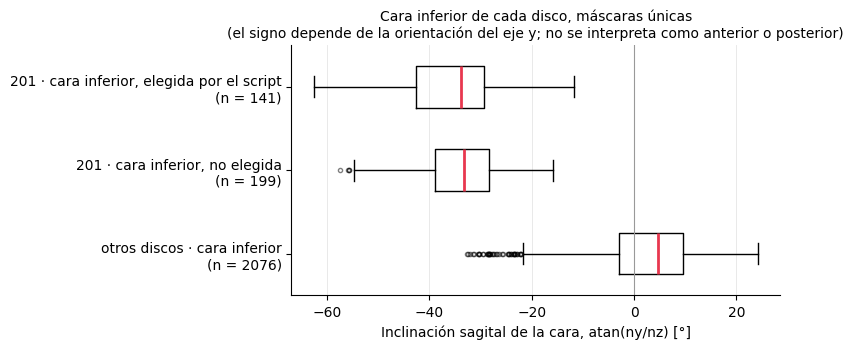

In [22]:
# 7b. Inclinación sagital de la cara inferior del 201 frente a las demás caras inferiores (máscaras únicas)
unicas = set(var.loc[var["mascara_unica"], "serie"])
inf_u = planos[(planos["cara"] == "inferior") & planos["serie"].isin(unicas)].copy()
inf_u["abs_sagital"] = inf_u["inclinacion_sagital"].abs()
inf_u["grupo"] = np.where(inf_u["disco"] != DISCO_CAUDAL, "otros discos · cara inferior",
                  np.where(inf_u["elegida_script"], "201 · cara inferior, elegida por el script",
                           "201 · cara inferior, no elegida"))
resumen_sag = (inf_u.groupby("grupo")[["inclinacion_sagital", "abs_sagital", "angulo_coronal_script", "arcsen_nx"]]
                    .describe(percentiles=[.25, .5, .75]).round(1))
resumen_sag.to_csv(DIR_SALIDA / "resumen_inclinacion_sagital.csv")
print(inf_u.groupby("grupo")["abs_sagital"].describe(percentiles=[.25, .5, .75]).round(1).to_string())

grupos = ["otros discos · cara inferior", "201 · cara inferior, no elegida", "201 · cara inferior, elegida por el script"]
grupos = [g for g in grupos if g in set(inf_u["grupo"])]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([inf_u.loc[inf_u["grupo"] == g, "inclinacion_sagital"] for g in grupos], vert=False, widths=0.5,
           tick_labels=[f"{g}\n(n = {(inf_u['grupo'] == g).sum()})" for g in grupos],
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.axvline(0, color="#999999", lw=0.8)
ax.set_xlabel("Inclinación sagital de la cara, atan(ny/nz) [°]")
ax.set_title("Cara inferior de cada disco, máscaras únicas\n(el signo depende de la orientación del eje y; no se interpreta como anterior o posterior)", fontsize=10)
ax.grid(axis="x", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_inclinacion_sagital.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la gráfica:** cada caja resume la inclinación sagital de un grupo de caras inferiores; la línea roja es la mediana. El signo depende de la orientación del eje $y$, que este cuaderno no verifica contra la anatomía, por eso la tabla también reporta el valor absoluto.

**Qué muestra:** la cara inferior del disco 201 está mucho más inclinada en sentido sagital que la del resto de los discos: su inclinación absoluta tiene una mediana de unos 33° a 34°, frente a 7,8° en las demás caras inferiores, y en la gráfica aparece al otro lado del cero. Es lo esperable si el disco 201 corresponde a la unión lumbosacra, aunque esa correspondencia no se verifica aquí. Sin embargo, las caras del 201 que el script eligió y las que no eligió tienen inclinaciones sagitales parecidas (medianas de 33,9° y 33,2°). Por lo tanto, la inclinación sagital por sí sola no explica cuándo el script elige esa cara; las celdas 7e y 7g retoman esta pregunta.

Diferencia original − variante, en grados (positivo: la variante da un ángulo menor)
        conjunto  variante   n  series_sin_cambio  mediana  p25  p75  minimo  maximo  cambia_par
todas las series A_sin_201 447                266     0.00 0.00 1.14    0.00   25.28         181
todas las series  B_arcsen 447                  0     0.20 0.06 0.51   -0.82   14.37          43
todas las series        AB 447                  0     0.30 0.08 1.17   -0.01   25.39         187
 máscaras únicas A_sin_201 340                199     0.00 0.00 1.14    0.00   25.28         141
 máscaras únicas  B_arcsen 340                  0     0.20 0.05 0.52   -0.82   14.37          35
 máscaras únicas        AB 340                  0     0.33 0.07 1.17   -0.01   25.39         145


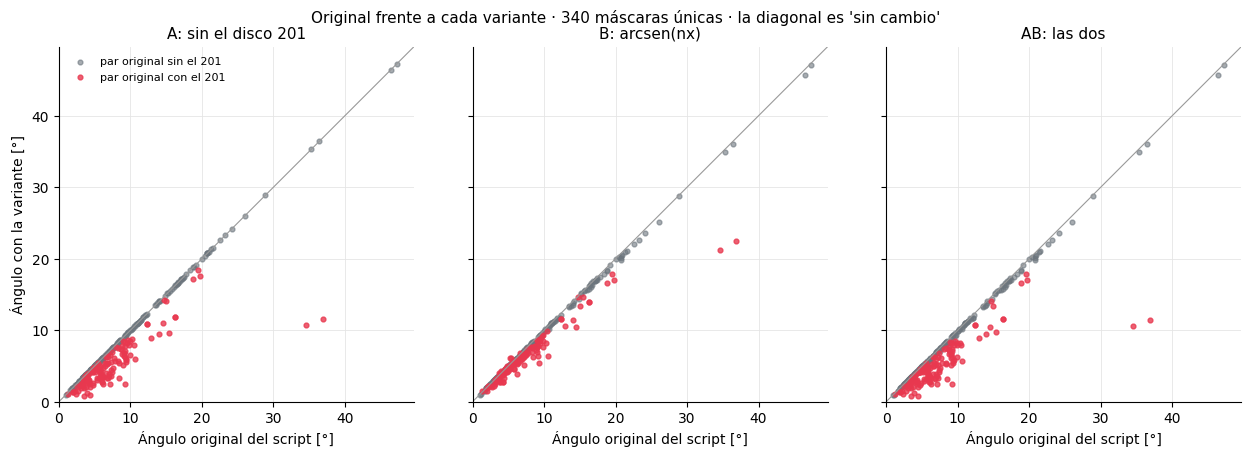

In [23]:
# 7c. Cuánto cambia el ángulo con cada variante
filas = []
for conjunto, df in (("todas las series", var), ("máscaras únicas", var[var["mascara_unica"]])):
    for nombre in ("A_sin_201", "B_arcsen", "AB"):
        d = df[f"dif_original_menos_{nombre}"]
        filas.append({"conjunto": conjunto, "variante": nombre, "n": int(d.notna().sum()),
                      "series_sin_cambio": int((d.abs() < 1e-9).sum()),
                      "mediana": d.median(), "p25": d.quantile(.25), "p75": d.quantile(.75),
                      "minimo": d.min(), "maximo": d.max(),
                      "cambia_par": int(df[f"cambia_par_{nombre}"].sum())})
resumen_var = pd.DataFrame(filas).round(2)
resumen_var.to_csv(DIR_SALIDA / "resumen_variantes.csv", index=False)
print("Diferencia original − variante, en grados (positivo: la variante da un ángulo menor)")
print(resumen_var.to_string(index=False))

u = var[var["mascara_unica"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
limite = np.nanmax(u[["angulo_original", "angulo_A_sin_201", "angulo_B_arcsen", "angulo_AB"]].to_numpy()) * 1.05
for ax, nombre, titulo in zip(axes, ("A_sin_201", "B_arcsen", "AB"),
                              ("A: sin el disco 201", "B: arcsen(nx)", "AB: las dos")):
    con_201 = u["par_original_incluye_201"]
    ax.plot([0, limite], [0, limite], color="#999999", lw=0.8)
    ax.scatter(u.loc[~con_201, "angulo_original"], u.loc[~con_201, f"angulo_{nombre}"], s=12, color="#6c757d",
               alpha=0.6, label="par original sin el 201")
    ax.scatter(u.loc[con_201, "angulo_original"], u.loc[con_201, f"angulo_{nombre}"], s=12, color="#e8384f",
               alpha=0.8, label="par original con el 201")
    ax.set_title(titulo, fontsize=11); ax.set_xlabel("Ángulo original del script [°]")
    ax.set_xlim(0, limite); ax.set_ylim(0, limite); ax.set_aspect("equal")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
axes[0].set_ylabel("Ángulo con la variante [°]")
axes[0].legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle(f"Original frente a cada variante · {len(u)} máscaras únicas · la diagonal es 'sin cambio'", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_original_vs_variantes.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la tabla y las gráficas:** la tabla resume la diferencia entre el ángulo original y cada variante; un valor positivo significa que la variante da un ángulo menor. En las gráficas, cada punto es una máscara única, y los puntos sobre la diagonal son los que no cambian. Los puntos rojos son las máscaras cuyo par original incluye el disco 201.

**Qué muestra:** la variante A no cambia nada en 199 de las 340 máscaras únicas, que son justamente las que no usaban el 201, y por eso su mediana global es 0. Cuando sí actúa, todos los puntos quedan por debajo de la diagonal, y la mayor reducción, de 25,28°, corresponde al estudio 162. La variante B cambia todos los ángulos, pero muy poco: la mediana de la diferencia es 0,20°, y su mínimo negativo (−0,82°) muestra que en algunas máscaras B da un ángulo mayor que el original, como anticipaba la definición matemática. En la gráfica de B, los puntos que más se alejan de la diagonal son rojos, es decir, el efecto de la fórmula también se concentra donde participa el 201. AB se comporta casi igual que A, porque al retirar el 201 desaparece la cara donde B tiene más efecto.

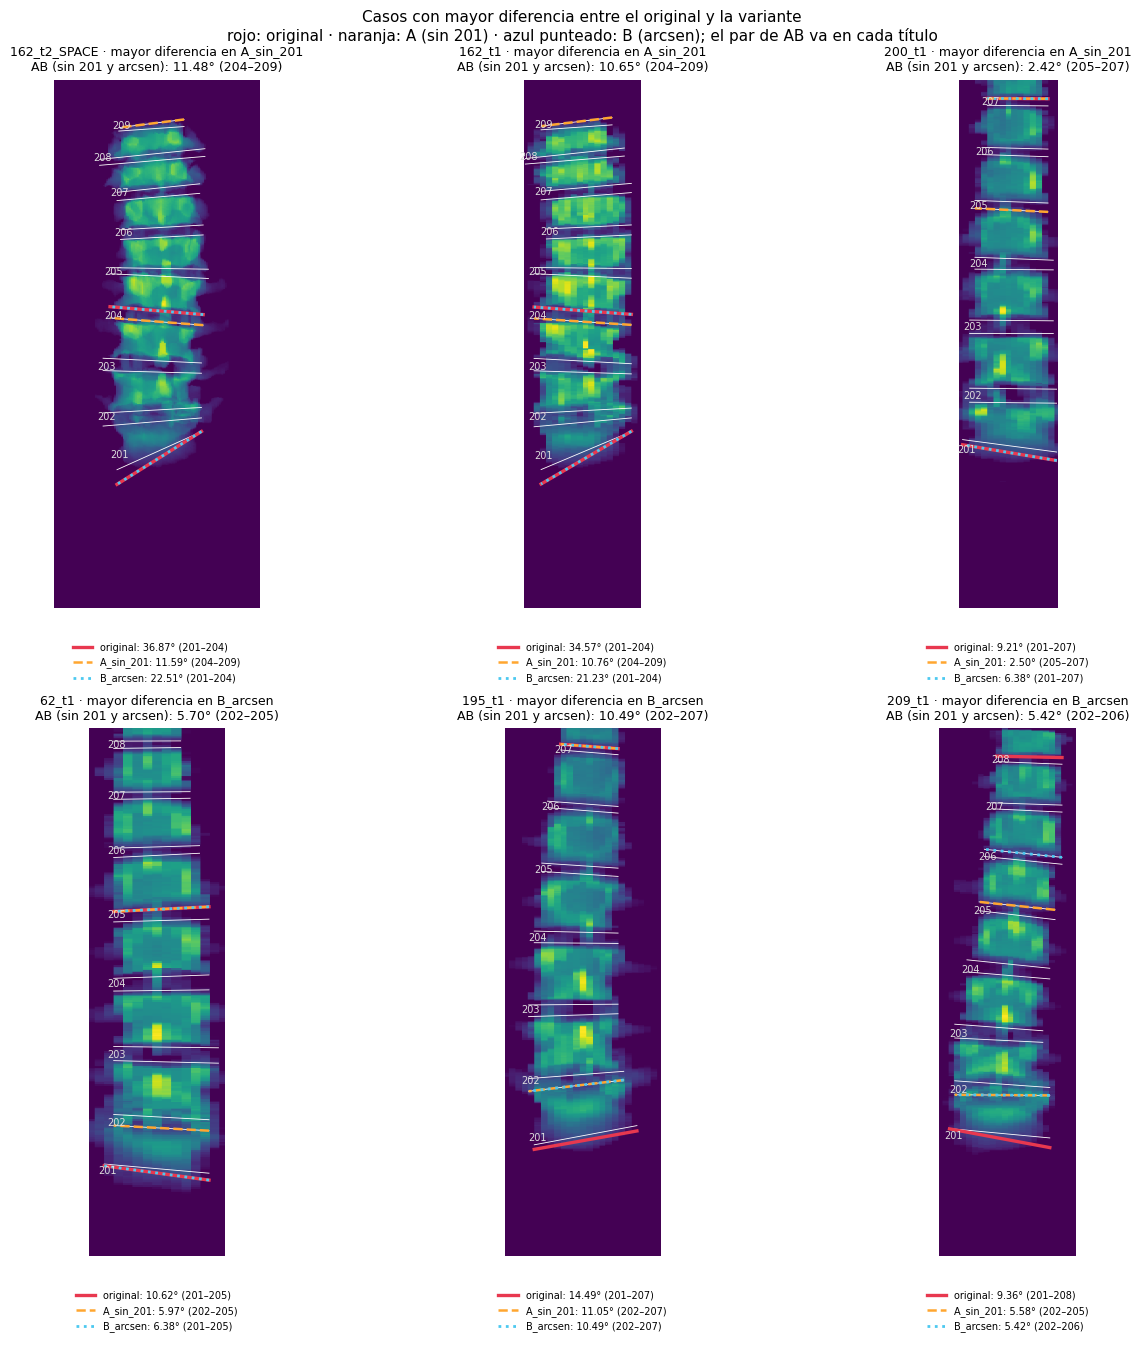

       serie seleccionada_por secuencia  angulo_original  angulo_A_sin_201  angulo_B_arcsen  angulo_AB  disco_inf_original  disco_sup_original
162_t2_SPACE        A_sin_201  t2_SPACE            36.87             11.59            22.51      11.48                 201                 204
      162_t1        A_sin_201        t1            34.57             10.76            21.23      10.65                 201                 204
      200_t1        A_sin_201        t1             9.21              2.50             6.38       2.42                 201                 207
       62_t1         B_arcsen        t1            10.62              5.97             6.38       5.70                 201                 205
      195_t1         B_arcsen        t1            14.49             11.05            10.49      10.49                 201                 207
      209_t1         B_arcsen        t1             9.36              5.58             5.42       5.42                 201                 208

In [24]:
# 7d. Casos con mayor diferencia (máscaras únicas): los N_EXTREMOS mayores por A y por B
N_EXTREMOS = 3   # @param {type:"integer"}
u = var[var["mascara_unica"]]
seleccion = []
for nombre in ("A_sin_201", "B_arcsen"):
    orden_dif = u[f"dif_original_menos_{nombre}"].abs().sort_values(ascending=False)
    orden_dif = orden_dif[orden_dif > 1e-9]                        # solo series en que la variante sí cambia el ángulo
    for serie in u.loc[orden_dif.index, "serie"]:
        if serie not in [s for s, _ in seleccion]:
            seleccion.append((serie, nombre))
        if sum(1 for _, n in seleccion if n == nombre) == N_EXTREMOS:
            break
extremos = var.set_index("serie").loc[[s for s, _ in seleccion]].reset_index()
extremos.insert(1, "seleccionada_por", [n for _, n in seleccion])
extremos.to_csv(DIR_EXTREMOS / "casos_extremos.csv", index=False)

columnas = min(3, len(seleccion)); filas_fig = int(np.ceil(len(seleccion) / columnas))
fig, axes = plt.subplots(filas_fig, columnas, figsize=(4.8 * columnas, 6.8 * filas_fig), squeeze=False)
for ax, (serie, nombre) in zip(axes.ravel(), seleccion):
    ns = ejecutar_script(DIR_LOCAL / f"{serie}.mha")          # unos 14 s por serie
    dibujar_variantes(ax, f"{serie} · mayor diferencia en {nombre}", ns, var.set_index("serie").loc[serie])
for ax in axes.ravel()[len(seleccion):]:
    ax.axis("off")
fig.suptitle("Casos con mayor diferencia entre el original y la variante\n"
             "rojo: original · naranja: A (sin 201) · azul punteado: B (arcsen); el par de AB va en cada título", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_EXTREMOS / "panel_casos_extremos.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()
print(extremos[["serie", "seleccionada_por", "secuencia", "angulo_original", "angulo_A_sin_201",
                "angulo_B_arcsen", "angulo_AB", "disco_inf_original", "disco_sup_original"]].round(2).to_string(index=False))

**Cómo leer el panel:** cada imagen es la proyección coronal que usa el script, con todas las caras discales en blanco y la etiqueta de cada disco al lado. Encima se dibuja el par que elige cada variante: rojo continuo para el original, naranja discontinuo para A y azul punteado para B, que se dibuja al final para que no quede oculto; el par de AB va en el título. Cuando dos variantes eligen el mismo par, sus líneas se superponen. La celda toma las `N_EXTREMOS` máscaras únicas con mayor diferencia frente a A y otras tantas frente a B, así que al cambiar ese valor cambian los casos mostrados.

**Con el valor por defecto (`N_EXTREMOS = 3`):** los casos de A son las dos máscaras distintas del estudio 162 (T1 y T2 SPACE) y la serie 200_t1; los de B son 62_t1, 195_t1 y 209_t1. Los seis tienen algo en común: en todos, el par original usa la cara inferior del disco 201, incluso en los que se seleccionaron por la diferencia con B. En el estudio 162, esa cara está visiblemente más inclinada que el resto de la columna; al retirarla, el par se desplaza a 204–209, mientras que B reduce el ángulo pero sigue eligiendo el par 201–204.

## Qué hace distinta a la cara inferior del disco 201

Las celdas anteriores muestran cuánto pesa el disco 201 en el resultado; las siguientes buscan entender por qué. La 7e compara la inclinación lateral de su cara inferior con la del resto, usando las dos fórmulas. La 7f comprueba con los datos la relación exacta entre ambas fórmulas que se describe en la definición matemática. La 7g relaciona el tamaño del efecto de la variante A con la inclinación de esa cara, y la 7h revisa si las caras que elige el script se ajustaron con menos vértices, lo que indicaría ajustes menos confiables. Todo se calcula desde `planos_por_disco.csv` y `angulos_variantes.csv`, sin volver a correr el script.

Inclinación lateral de cada cara inferior, en valor absoluto [°]

fórmula del script, atan(nx/nz)
                                             count  mean  std  min  25%  50%  75%   max
grupo                                                                                  
201 · cara inferior, elegida por el script   141.0   4.2  4.0  0.0  2.3  3.4  5.2  32.0
201 · cara inferior, no elegida              199.0   2.2  2.2  0.0  0.7  1.6  2.8  11.7
otros discos · cara inferior                2076.0   2.9  3.0  0.0  1.0  2.1  3.8  24.8

arcsen(nx)
                                             count  mean  std  min  25%  50%  75%   max
grupo                                                                                  
201 · cara inferior, elegida por el script   141.0   3.1  2.4  0.0  1.9  2.7  4.1  17.7
201 · cara inferior, no elegida              199.0   1.8  1.8  0.0  0.6  1.3  2.3  10.3
otros discos · cara inferior                2076.0   2.9  3.0  0.0  1.0  2.1  3.8  24.8


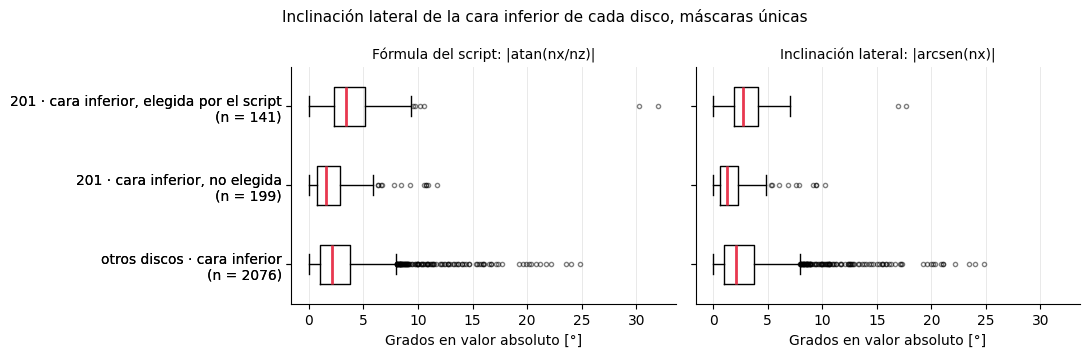

In [25]:
# 7e. ¿Cuánta inclinación lateral tiene de verdad la cara inferior del 201? (máscaras únicas)
inf_u["abs_coronal_script"] = inf_u["angulo_coronal_script"].abs()
inf_u["abs_arcsen"] = inf_u["arcsen_nx"].abs()
resumen_lat = (inf_u.groupby("grupo")[["abs_coronal_script", "abs_arcsen"]]
                    .describe(percentiles=[.25, .5, .75]).round(1))
resumen_lat.to_csv(DIR_SALIDA / "resumen_inclinacion_lateral.csv")
print("Inclinación lateral de cada cara inferior, en valor absoluto [°]")
for col, nombre in (("abs_coronal_script", "fórmula del script, atan(nx/nz)"), ("abs_arcsen", "arcsen(nx)")):
    print(f"\n{nombre}")
    print(inf_u.groupby("grupo")[col].describe(percentiles=[.25, .5, .75]).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, sharex=True)
for ax, col, titulo in zip(axes, ("abs_coronal_script", "abs_arcsen"),
                           ("Fórmula del script: |atan(nx/nz)|", "Inclinación lateral: |arcsen(nx)|")):
    ax.boxplot([inf_u.loc[inf_u["grupo"] == g, col] for g in grupos], vert=False, widths=0.5,
               tick_labels=[f"{g}\n(n = {(inf_u['grupo'] == g).sum()})" for g in grupos],
               medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Grados en valor absoluto [°]")
    ax.grid(axis="x", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
fig.suptitle("Inclinación lateral de la cara inferior de cada disco, máscaras únicas", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_inclinacion_lateral.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer las gráficas:** los mismos tres grupos de 7b, ahora con la inclinación lateral de cada cara en valor absoluto. El panel izquierdo usa la fórmula del script y el derecho, $\arcsin(n_x)$.

**Qué muestra:** con la fórmula del script, las caras inferiores del 201 que fueron elegidas tienen una mediana de 3,4° de inclinación lateral, frente a 1,6° en las no elegidas y 2,1° en las caras inferiores del resto; con $\arcsin(n_x)$, esas medianas son 2,7°, 1,3° y 2,1°. De aquí se desprenden dos cosas. Primero, en los demás discos las dos fórmulas casi coinciden, mientras que en el 201 la del script da valores mayores, por la amplificación que describe la definición matemática. Segundo, aun con $\arcsin(n_x)$, las caras del 201 que el script eligió están más inclinadas lateralmente que las que no eligió. Por lo tanto, la elección no se explica solo por la amplificación sagital: esas caras sí tienen algo más de inclinación lateral. Los dos valores atípicos, de 30,3° y 32,0° con la fórmula del script (17,0° y 17,7° con $\arcsin(n_x)$), son las dos máscaras del estudio 162.

Caras con |arcsen(nx)| > 0,5°: 4200 de 4832 · error relativo máximo frente a 1/cos(φ): 8.9e-16
                     mediana |φ| [°]  mediana 1/cos(φ)  mediana |θ_orig| − |θ_B| [°]
grupo                                                                               
201 · cara inferior           33.331             1.197                         0.339
resto de las caras             8.373             1.011                         0.018


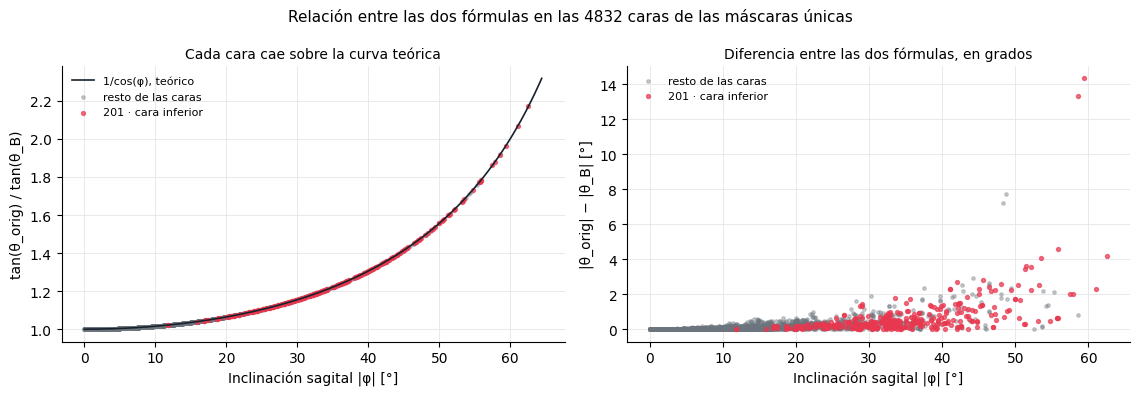

In [26]:
# 7f. Comprobación empírica de la relación entre las dos fórmulas: tan(θ_orig) = tan(θ_B) / cos(φ_sagital)
caras_u = planos[planos["serie"].isin(unicas)].copy()
caras_u["abs_sagital"] = caras_u["inclinacion_sagital"].abs()
caras_u["factor"] = 1 / np.cos(np.radians(caras_u["inclinacion_sagital"]))      # cuánto se amplifica tan(θ)
caras_u["dif_por_cara"] = caras_u["angulo_coronal_script"].abs() - caras_u["arcsen_nx"].abs()
con_lateral = caras_u["arcsen_nx"].abs() > 0.5                                   # el cociente no se define si nx ≈ 0
cociente = (np.tan(np.radians(caras_u["angulo_coronal_script"])) / np.tan(np.radians(caras_u["arcsen_nx"])))[con_lateral]
error_rel = (cociente - caras_u.loc[con_lateral, "factor"]).abs() / caras_u.loc[con_lateral, "factor"]
print(f"Caras con |arcsen(nx)| > 0,5°: {con_lateral.sum()} de {len(caras_u)} · "
      f"error relativo máximo frente a 1/cos(φ): {error_rel.max():.1e}")
assert error_rel.max() < 1e-6, "La relación entre las dos fórmulas no se cumple: revisar normales e inclinaciones"

es_201_inf = (caras_u["disco"] == DISCO_CAUDAL) & (caras_u["cara"] == "inferior")
tabla_f = (caras_u.assign(grupo=np.where(es_201_inf, "201 · cara inferior", "resto de las caras"))
                  .groupby("grupo")[["abs_sagital", "factor", "dif_por_cara"]].median().round(3))
tabla_f.columns = ["mediana |φ| [°]", "mediana 1/cos(φ)", "mediana |θ_orig| − |θ_B| [°]"]
print(tabla_f.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
phi = np.linspace(0, caras_u["abs_sagital"].max() * 1.03, 200)
ax = axes[0]
ax.plot(phi, 1 / np.cos(np.radians(phi)), color="#18212b", lw=1.2, label="1/cos(φ), teórico")
ax.scatter(caras_u.loc[con_lateral & ~es_201_inf, "abs_sagital"], cociente[~es_201_inf[con_lateral]],
           s=6, color="#6c757d", alpha=0.35, label="resto de las caras")
ax.scatter(caras_u.loc[con_lateral & es_201_inf, "abs_sagital"], cociente[es_201_inf[con_lateral]],
           s=8, color="#e8384f", alpha=0.7, label="201 · cara inferior")
ax.set_xlabel("Inclinación sagital |φ| [°]"); ax.set_ylabel("tan(θ_orig) / tan(θ_B)")
ax.set_title("Cada cara cae sobre la curva teórica", fontsize=10)
ax = axes[1]
ax.scatter(caras_u.loc[~es_201_inf, "abs_sagital"], caras_u.loc[~es_201_inf, "dif_por_cara"],
           s=6, color="#6c757d", alpha=0.35, label="resto de las caras")
ax.scatter(caras_u.loc[es_201_inf, "abs_sagital"], caras_u.loc[es_201_inf, "dif_por_cara"],
           s=8, color="#e8384f", alpha=0.7, label="201 · cara inferior")
ax.set_xlabel("Inclinación sagital |φ| [°]"); ax.set_ylabel("|θ_orig| − |θ_B| [°]")
ax.set_title("Diferencia entre las dos fórmulas, en grados", fontsize=10)
for ax in axes:
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True); ax.legend(fontsize=8, frameon=False)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
fig.suptitle(f"Relación entre las dos fórmulas en las {len(caras_u)} caras de las máscaras únicas", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_relacion_formulas.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer las gráficas:** en el panel izquierdo, cada punto es una cara con inclinación lateral apreciable, y la curva negra es el factor teórico $1/\cos\varphi$; si la relación de la definición matemática se cumple, todos los puntos caen sobre ella. El panel derecho muestra la misma comparación en grados: cuánto mayor es la inclinación lateral con la fórmula del script que con $\arcsin(n_x)$.

**Qué muestra:** en las 4200 caras con inclinación lateral mayor de 0,5°, el cociente entre las tangentes coincide con $1/\cos\varphi$ con un error relativo del orden de $10^{-15}$. Por lo tanto, la relación es exacta y las dos fórmulas están implementadas de forma consistente; si no se cumpliera, la celda se detendría. La mediana del factor de amplificación es 1,197 en la cara inferior del 201 y 1,011 en el resto: la fórmula del script infla la tangente de esa cara cerca de un 20 %, mientras que en las demás caras apenas un 1 %. En grados, la diferencia mediana por cara es de 0,34° en el 201 y de 0,02° en el resto. Es pequeña porque la mayoría de las caras tienen poca inclinación lateral, y crece cuando coinciden mucha inclinación sagital y lateral, como en los puntos de la derecha del panel, entre los que hay también algunas caras de otros discos.

Máscaras únicas con el 201 en el par original: 141
Reducción del ángulo con A en esas máscaras: mediana 1.44°, p25 0.65°, p75 2.64° · mayor de 2°: 55 · mayor de 5°: 5
Correlación de Spearman con la reducción del ángulo al aplicar A:
  inclinación sagital de la cara inferior del 201: 0.20
  ángulo coronal del script en esa misma cara:     0.51


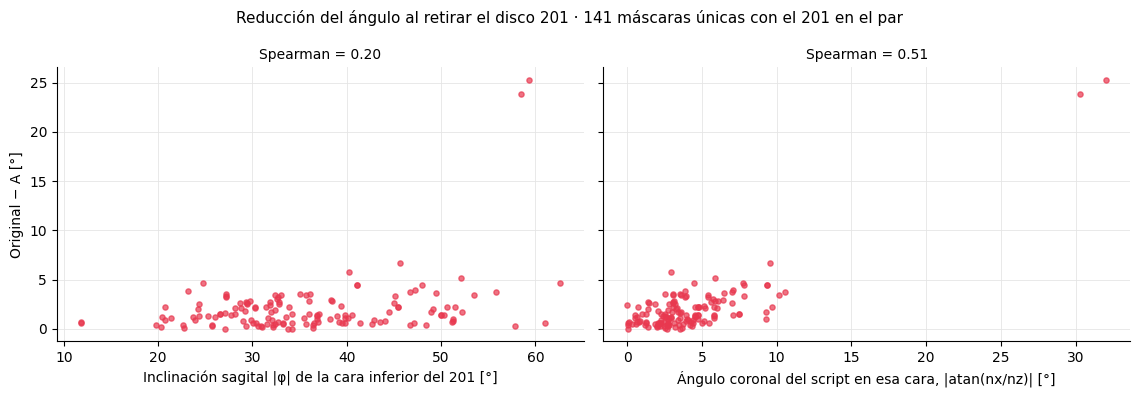

In [27]:
# 7g. ¿El efecto de retirar el 201 crece con la inclinación de su cara inferior? (máscaras únicas con el 201 en el par)
cara_201 = (planos[(planos["disco"] == DISCO_CAUDAL) & (planos["cara"] == "inferior")]
            .set_index("serie")[["inclinacion_sagital", "angulo_coronal_script"]])
con_201 = var[var["mascara_unica"] & var["par_original_incluye_201"]].join(cara_201, on="serie")
con_201["abs_sagital_201"] = con_201["inclinacion_sagital"].abs()
con_201["abs_coronal_201"] = con_201["angulo_coronal_script"].abs()
y = con_201["dif_original_menos_A_sin_201"]
rho = {col: y.corr(con_201[col], method="spearman") for col in ("abs_sagital_201", "abs_coronal_201")}
print(f"Máscaras únicas con el 201 en el par original: {len(con_201)}")
print(f"Reducción del ángulo con A en esas máscaras: mediana {y.median():.2f}°, "
      f"p25 {y.quantile(.25):.2f}°, p75 {y.quantile(.75):.2f}° · mayor de 2°: {(y > 2).sum()} · mayor de 5°: {(y > 5).sum()}")
print(f"Correlación de Spearman con la reducción del ángulo al aplicar A:\n"
      f"  inclinación sagital de la cara inferior del 201: {rho['abs_sagital_201']:.2f}\n"
      f"  ángulo coronal del script en esa misma cara:     {rho['abs_coronal_201']:.2f}")
con_201[["serie", "abs_sagital_201", "abs_coronal_201", "angulo_original", "angulo_A_sin_201",
         "dif_original_menos_A_sin_201"]].to_csv(DIR_SALIDA / "efecto_A_vs_cara_201.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
for ax, col, etiqueta in zip(axes, ("abs_sagital_201", "abs_coronal_201"),
                             ("Inclinación sagital |φ| de la cara inferior del 201 [°]",
                              "Ángulo coronal del script en esa cara, |atan(nx/nz)| [°]")):
    ax.scatter(con_201[col], y, s=14, color="#e8384f", alpha=0.7)
    ax.set_xlabel(etiqueta); ax.set_title(f"Spearman = {rho[col]:.2f}", fontsize=10)
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
axes[0].set_ylabel("Original − A [°]")
fig.suptitle(f"Reducción del ángulo al retirar el disco 201 · {len(con_201)} máscaras únicas con el 201 en el par", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_efecto_A_vs_cara_201.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer las gráficas:** cada punto es una de las máscaras únicas cuyo par original incluye el disco 201. El eje vertical es cuánto baja el ángulo al retirar esa cara (variante A); el horizontal es, a la izquierda, su inclinación sagital y, a la derecha, su ángulo coronal según la fórmula del script. La correlación de Spearman mide si ambas cosas crecen juntas, sin suponer una relación lineal.

**Qué muestra:** en esas 141 máscaras, retirar la cara inferior del 201 reduce el ángulo una mediana de 1,44° (rango intercuartílico de 0,65° a 2,64°); la reducción supera 2° en 55 máscaras y 5° en solo 5. La reducción se relaciona poco con la inclinación sagital de la cara (Spearman de 0,20) y bastante más con su ángulo coronal (0,51). Esta segunda relación es en parte mecánica, porque el ángulo coronal de esa cara entra directamente en el cálculo del original. Aun así, indica que lo que más pesa es cuánto aparenta inclinarse lateralmente la cara en la proyección coronal, y que la inclinación sagital influye sobre todo a través de la amplificación que muestra 7f. Las dos máscaras del extremo superior derecho son las del estudio 162, que además tienen la inclinación sagital más alta del grupo (unos 59°).

Vértices relativos = vértices de la cara / mediana de las caras de la misma serie
                                  count  mean   std   min   10%   25%   50%   75%   max
grupo_ajuste                                                                           
resto · cara no elegida          3953.0  0.95  0.24  0.29  0.63  0.77  0.99  1.11  1.88
resto · cara elegida              539.0  0.97  0.24  0.39  0.65  0.77  1.00  1.14  1.73
201 · cara inferior, no elegida   199.0  1.15  0.18  0.59  0.99  1.03  1.14  1.26  1.78
201 · cara inferior, elegida      141.0  1.22  0.19  0.79  1.00  1.09  1.18  1.33  1.79


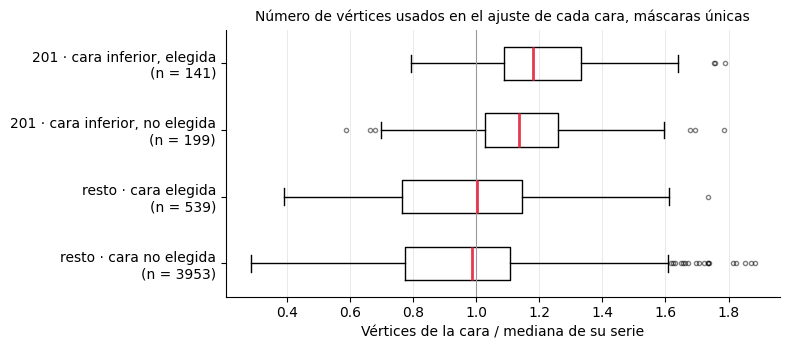

In [28]:
# 7h. Calidad del ajuste: ¿las caras que elige el script se ajustaron con menos vértices? (máscaras únicas)
caras_u["vertices_relativos"] = caras_u["n_vertices"] / caras_u.groupby("serie")["n_vertices"].transform("median")
caras_u["grupo_ajuste"] = np.select(
    [es_201_inf & caras_u["elegida_script"], es_201_inf, caras_u["elegida_script"]],
    ["201 · cara inferior, elegida", "201 · cara inferior, no elegida", "resto · cara elegida"],
    default="resto · cara no elegida")
orden_aj = ["resto · cara no elegida", "resto · cara elegida", "201 · cara inferior, no elegida", "201 · cara inferior, elegida"]
resumen_aj = (caras_u.groupby("grupo_ajuste")[["n_vertices", "vertices_relativos"]]
                     .describe(percentiles=[.1, .25, .5, .75]).round(2).reindex(orden_aj))
resumen_aj.to_csv(DIR_SALIDA / "resumen_vertices_por_cara.csv")
print("Vértices relativos = vértices de la cara / mediana de las caras de la misma serie")
print(caras_u.groupby("grupo_ajuste")["vertices_relativos"].describe(percentiles=[.1, .25, .5, .75])
             .round(2).reindex(orden_aj).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([caras_u.loc[caras_u["grupo_ajuste"] == g, "vertices_relativos"] for g in orden_aj], vert=False, widths=0.5,
           tick_labels=[f"{g}\n(n = {(caras_u['grupo_ajuste'] == g).sum()})" for g in orden_aj],
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.axvline(1, color="#999999", lw=0.8)
ax.set_xlabel("Vértices de la cara / mediana de su serie")
ax.set_title("Número de vértices usados en el ajuste de cada cara, máscaras únicas", fontsize=10)
ax.grid(axis="x", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_vertices_por_cara.png", dpi=150, facecolor="white")
plt.show()

**Cómo leer la gráfica:** el número de vértices con que se ajustó cada cara depende del tamaño del disco y del paciente, por eso se divide por la mediana de las caras de la misma serie. Un valor de 1 corresponde a una cara de tamaño típico para esa columna, y valores bajos señalan caras ajustadas con pocos puntos, cuyo plano es menos confiable.

**Qué muestra:** las caras que elige el script no se ajustaron con menos vértices que las demás: en el resto de los discos, las medianas relativas son 1,00 para las elegidas y 0,99 para las no elegidas. Por lo tanto, no hay indicios de que el algoritmo prefiera caras con ajustes pobres. La cara inferior del 201, en cambio, tiene más vértices que la mediana de su serie (1,14 cuando no se elige y 1,18 cuando se elige). Esto puede reflejar el tamaño del disco o su inclinación, que hace que la cara ocupe más vóxeles, pero este cuaderno no permite separar ambas explicaciones.

## Síntesis y preguntas abiertas

La pregunta de este cuaderno era si lo observado en la serie 162 es un caso aislado. En frecuencia no lo es: la cara inferior del disco 201 forma parte del par elegido en cuatro de cada diez máscaras, en las tres secuencias. En magnitud, sí es excepcional: en la mayoría de esas máscaras retirar esa cara cambia el ángulo en un grado y medio o menos, y el estudio 162 es, de lejos, el caso con mayor efecto.

Las celdas 7e a 7h ayudan a entender el mecanismo. La cara inferior del 201 está muy inclinada en sentido sagital, y la fórmula del script amplifica su inclinación lateral cerca de un 20 %. Sin embargo, esa amplificación no basta para explicar por qué el script la elige: las caras elegidas también tienen más inclinación lateral real, y el efecto de retirarlas se relaciona más con su ángulo coronal que con su inclinación sagital. Tampoco hay indicios de que el algoritmo prefiera caras ajustadas con pocos vértices. Cambiar de fórmula (variante B) reduce el ángulo apenas unas décimas de grado en general, aunque más en las máscaras donde participa el 201.

Estas diferencias son cambios en la salida del algoritmo, no diferencias demostradas en la curvatura anatómica real. Sin un ángulo de Cobb de referencia medido por especialistas, no es posible decir cuál de las cuatro columnas se acerca más a la medida correcta.

**Pregunta abierta: el extremo craneal.** Al revisar los pares elegidos apareció una pregunta que este cuaderno no aborda porque se aleja de su objetivo. En 115 de las 340 máscaras únicas, la cara superior del par elegido pertenece al disco más craneal de la máscara; en 31, el par usa a la vez ese disco y el 201, y con la variante A el disco más craneal pasa a usarse en 139. Que el máximo caiga en los extremos es en parte esperable, porque un rango más amplio de discos permite diferencias mayores y las vértebras límite de una curva pueden estar cerca del borde del campo de visión. Sin embargo, el disco más craneal también puede quedar segmentado de forma incompleta en ese borde. Determinar si esas caras son confiables, y cuánto cambia el ángulo al excluirlas, queda abierto. Los datos necesarios para empezar ya están en `planos_por_disco.csv` y `angulos_variantes.csv`, y cualquier aporte es bienvenido a través de los issues del repositorio.

## Guía de la carpeta de resultados

La celda 8 escribe `LEEME.md` en la carpeta de resultados, con lo que contiene cada archivo y el enlace a las figuras originales del script de la semana 1. Así, quien llegue solo a esta carpeta sabe qué mirar sin que se dupliquen las 447 figuras de la semana 1.

In [29]:
# 8. LEEME.md de la carpeta de resultados
leeme = f"""# 03 · El disco más caudal (201) y tres variantes del ángulo

Resultados de `notebooks/03_disco_caudal_y_variantes.ipynb`. Solo investigación; no es para diagnóstico.
Los ángulos salen de las máscaras manuales de SPIDER v4 con `compute-Cobb-angle.py` (commit `{COMMIT_SCRIPT[:7]}`);
no hay Cobb de referencia, así que ninguna variante se presenta como la correcta.

| Archivo | Qué contiene |
|-|-|
| `planos_por_disco.csv` | Una fila por cara de disco y serie: normal y punto del plano del script, ángulo coronal del script, arcsen(nx), inclinación sagital y si la cara forma parte del par elegido |
| `registro_corrida.csv` | Una fila por serie: ángulo del script, número de discos, estado y tiempo |
| `angulos_variantes.csv` | Una fila por serie: ángulo y par de discos del original y de las variantes A (sin 201), B (arcsen) y AB, diferencias y huella de la máscara |
| `resumen_disco_201.csv` | Series en que el par original incluye el disco 201 y series que cambian de par, con y sin máscaras duplicadas |
| `resumen_inclinacion_sagital.csv`, `figura_inclinacion_sagital.png` | Inclinación sagital de la cara inferior del 201 frente a las demás caras inferiores |
| `resumen_variantes.csv`, `figura_original_vs_variantes.png` | Cuánto cambia el ángulo con cada variante |
| `resumen_inclinacion_lateral.csv`, `figura_inclinacion_lateral.png` | Inclinación lateral de la cara inferior del 201 frente a las demás, con las dos fórmulas |
| `figura_relacion_formulas.png` | Comprobación de la relación exacta entre la fórmula del script y arcsen(nx) en cada cara |
| `efecto_A_vs_cara_201.csv`, `figura_efecto_A_vs_cara_201.png` | Reducción del ángulo al retirar el 201 frente a la inclinación de su cara inferior |
| `resumen_vertices_por_cara.csv`, `figura_vertices_por_cara.png` | Número de vértices usados en el ajuste de cada cara, absoluto y relativo a su serie |
| `figuras_variantes/` | Una figura por serie con el par que elige cada variante |
| `casos_extremos/` | Panel y tabla de los casos con mayor diferencia |
| `entorno.json` | Versiones, commits y huellas de la corrida |

Las figuras originales del script (sin variantes) son idénticas a las de la semana 1 y están en
[`resultados_semana1/02_compute-Cobb-angle/figuras/`](../../resultados_semana1/02_compute-Cobb-angle/figuras/).
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 03 · El disco más caudal (201) y tres variantes del ángulo

Resultados de `notebooks/03_disco_caudal_y_variantes.ipynb`. Solo investigación; no es para diagnóstico.
Los ángulos salen de las máscaras manuales de SPIDER v4 con `compute-Cobb-angle.py` (commit `72c712f`);
no hay Cobb de referencia, así que ninguna variante se presenta como la correcta.

| Archivo | Qué contiene |
|-|-|
| `planos_por_disco.csv` | Una fila por cara de disco y serie: normal y punto del plano del script, ángulo coronal del script, arcsen(nx), inclinación sagital y si la cara forma parte del par elegido |
| `registro_corrida.csv` | Una fila por serie: ángulo del script, número de discos, estado y tiempo |
| `angulos_variantes.csv` | Una fila por serie: ángulo y par de discos del original y de las variantes A (sin 201), B (arcsen) y AB, diferencias y huella de la máscara |
| `resumen_disco_201.csv` | Series en que el par original incluye el disco 201 y series que cambian de par, con y sin máscaras duplicadas |

## Registro del entorno

La celda 9 guarda en `entorno.json` las versiones de Python y de las librerías, los commits y huellas del script y de Tiger, la huella de `masks.zip` y la definición de cada variante, para que la corrida pueda reproducirse y citarse.

In [30]:
# 9. Registro del entorno (para docs/fuentes_externas.md y para reproducir la corrida)
import json, sys, platform, datetime, importlib.metadata as md_
import skimage
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "numpy": np.__version__, "scikit-image": skimage.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "tiger": md_.version("tiger") if any(d.metadata["Name"].lower() == "tiger" for d in md_.distributions()) else "instalado desde git",
    "tiger_commit": COMMIT_TIGER, "script_commit": COMMIT_SCRIPT, "script_sha256": SHA256_SCRIPT,
    "adaptacion": "parte real de np.linalg.eig en PCA() para NumPy 2; validada contra NumPy 1.26 en 5 máscaras (cuaderno 02)",
    "masks_zip_md5": md5_zip, "n_mascaras": len(mascaras), "mascaras_distintas_en_drive": distintos,
    "largest_angle": True, "resolucion_resampleo_mm": [0.5, 0.5, 0.5],
    "variantes": {k: {"angulo_por_cara": c, "discos_excluidos": list(e)} for k, (c, e) in VARIANTES.items()},
    "n_caras_guardadas": int(len(planos)), "n_series_ok": int((registro["estado"] == "ok").sum()),
    "mascaras_unicas": int(var["mascara_unica"].sum()),
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False))
print(json.dumps(entorno, indent=2, ensure_ascii=False))
print("\nArchivos en la salida:", sorted(p.name for p in DIR_SALIDA.iterdir()),
      "| figuras de variantes:", len(list(DIR_FIGURAS.glob("*.png"))))

{
  "fecha": "2026-10-18T07:51:06",
  "python": "3.13.16",
  "plataforma": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "scikit-image": "0.25.2",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0",
  "tiger": "6.3.0",
  "tiger_commit": "4c63f6d58ed3f8e7a0cec04b0352949f7b512919",
  "script_commit": "72c712f31e1f3069aef77b98b20af448bbc5615a",
  "script_sha256": "4b6de7ca4f12b134dfb9fc6b373768a4a3b9a8763d66238b5798c7eaa7c89849",
  "adaptacion": "parte real de np.linalg.eig en PCA() para NumPy 2; validada contra NumPy 1.26 en 5 máscaras (cuaderno 02)",
  "masks_zip_md5": "49861ff25a0108b3b69d0ce808ae51dc",
  "n_mascaras": 447,
  "mascaras_distintas_en_drive": [],
  "largest_angle": true,
  "resolucion_resampleo_mm": [
    0.5,
    0.5,
    0.5
  ],
  "variantes": {
    "original": {
      "angulo_por_cara": "angulo_coronal_script",
      "discos_excluidos": []
    },
    "A_sin_201": {
      "angulo_por_cara": "angulo_coronal_script",
      "discos_excluidos": [
        201
   

**Criterio de cierre.** El cuaderno corre de principio a fin con *Entorno de ejecución → Reiniciar y ejecutar todo*, `registro_corrida.csv` tiene 447 series con estado `ok`, los controles 1, 2 y 4 de la celda 6 pasan, el control 3 no muestra diferencias con el cuaderno 02, la comprobación de la celda 7f pasa y `angulos_variantes.csv` tiene las cuatro columnas de ángulo para las 447 series. Antes de citar las cifras de las celdas 7a a 7h conviene revisar en `figuras_variantes/` los casos extremos y algunos casos al azar de cada grupo.